# Multimodal fusion lab: a controlled synthetic benchmark

**Goal.** Understand *when* early, intermediate and late fusion (linear or nonlinear) work, and why.
Because we generate the data ourselves, we know exactly how information is spread across modalities, so every
result can be explained instead of just observed.

| Scenario | Label depends on | Question it answers |
|---|---|---|
| **A** Redundancy | the same latent `s` seen by all modalities | does combining views help at all? |
| **B** Uniqueness | a different latent in each modality | do we need *all* modalities? |
| **C** Synergy | XOR of a bit in the image and a bit in the signal | what can late fusion *not* do? |
| **D** Imbalance | clean image + noisy signal | does joint training ignore the weak modality? |
| **E** Corruption | like A, but corrupted at test time | which fusion is robust? |

**How to work.** Cells marked **TODO** need your code. Cells marked **Predict** ask you to write down a hypothesis
*before* running the next cell. Everything runs on CPU in a few minutes.

Files needed next to this notebook: `multimodal_gen.py`.

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from multimodal_gen import (make_dataset, split_dataset, corrupt, handcrafted_features,
                            plot_samples, SCENARIOS, MODALITIES)

warnings.filterwarnings("ignore")
torch.set_num_threads(2); torch.manual_seed(0); np.random.seed(0)
MODS = list(MODALITIES)                      # ['img', 'sig', 'tab']
pd.options.display.float_format = "{:.3f}".format
for k, v in SCENARIOS.items(): print(k, v)

/Users/base/Documents/Université/MAHB/TP1/.venv/lib/python3.14/site-packages/sklearn/experimental/enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


A Redundancy  - every modality sees the same latent s
B Uniqueness  - each modality carries its own part of the label
C Synergy     - XOR of a bit in the image and a bit in the signal
D Imbalance   - easy/clean image vs. harder/noisier signal
E Corruption  - redundant data, corrupt a modality at test time


## Part 1: Look at the data

`make_dataset(scenario, n, noise, seed)` returns images, 1D signals, tabular vectors and a binary label.
It also stores `obs` (the noisy latent each modality was rendered from) and an **oracle** accuracy: the best any
model could do if it could read the latents directly (pixel noise makes it slightly optimistic).

scenario=A n=4000 noise=1.0 sigma(img,sig,tab)=(0.8, 0.8, 0.8) P(y=1)=0.49 oracle_acc=0.872
scenario=B n=4000 noise=1.0 sigma(img,sig,tab)=(0.5, 0.5, 0.5) P(y=1)=0.51 oracle_acc=0.850
scenario=C n=4000 noise=1.0 sigma(img,sig,tab)=(0.6, 0.6, 0.6) P(y=1)=0.51 oracle_acc=0.917
scenario=D n=4000 noise=1.0 sigma(img,sig,tab)=(0.2, 0.6, 0.6) P(y=1)=0.51 oracle_acc=0.883
scenario=E n=4000 noise=1.0 sigma(img,sig,tab)=(0.8, 0.8, 0.8) P(y=1)=0.49 oracle_acc=0.872


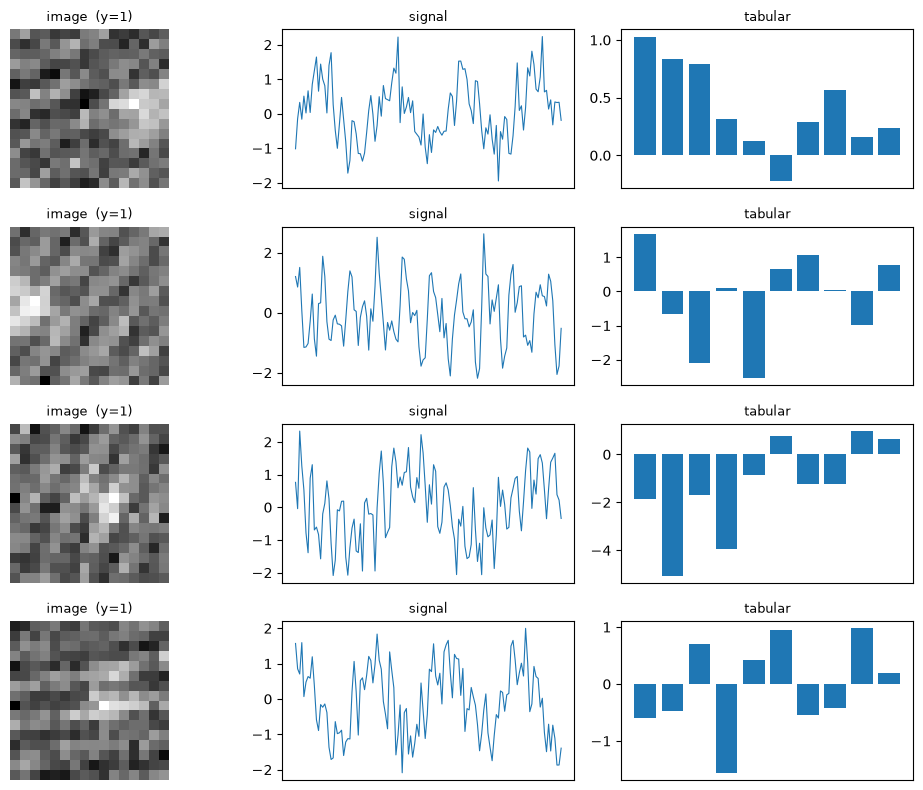

In [2]:
def load(scn, n=6000, noise=1.0, seed=0):
    return split_dataset(make_dataset(scn, n=n, noise=noise, seed=seed), (0.6, 0.2, 0.2), seed=seed)

for scn in SCENARIOS:
    print(make_dataset(scn, n=4000).summary())

tr, va, te = load("C")
fig = plot_samples(tr, n=4); plt.show()

**Exercise 1 (TODO).** For each scenario, compute how well *each modality alone* could predict `y`, using the oracle
view of that modality: predict `y = 1` if `data.obs[:, m] > 0` (column 0 = image, 1 = signal, 2 = tabular).
This is an upper bound on unimodal accuracy for A, C, and a rough proxy for B, D.

**Predict first:** which scenario should give ~50% for *every* single modality, and why?

In [11]:
def unimodal_oracle(data):
    # TODO: return a list with the accuracy of sign(obs[:, m]) as predictor of data.y, for m = 0, 1, 2
    scores =[]
    for m in range(3):
      modality=data.obs[:,m]
      predictions=modality>0
      accuracy=float((predictions==data.y).mean())
      scores.append(accuracy)
    return scores
      


for scn in SCENARIOS:
    d = make_dataset(scn, n=5000)
    print(scn, np.round(unimodal_oracle(d), 3), "| all-modality oracle:", round(d.oracle_accuracy(), 3))

A [0.786 0.785 0.799] | all-modality oracle: 0.869
B [0.692 0.696 0.633] | all-modality oracle: 0.852
C [0.5   0.493 0.502] | all-modality oracle: 0.915
D [0.751 0.708 0.513] | all-modality oracle: 0.885
E [0.786 0.785 0.799] | all-modality oracle: 0.869


**Answer.**

**Scenario C (Synergy)** is at 50% (~chance) for every single modality. 

In C, the label is $y = b_{\text{img}} \oplus b_{\text{sig}}$. Knowing $b_{\text{img}}$ alone gives exactly zero information about $y$ without knowing $b_{\text{sig}}$ (and vice versa), because $P(y=1 \mid b_{\text{img}}) = 0.5$. The tabular view is pure gaussian noise, so it is also at 50%. You need both modalities simultaneously to predict better than a coin flip.

## Part 2: The classical fusion grid with fixed features (sklearn)

Fixed features: flattened pixels, **FFT magnitudes** of the signal (its phase is random, so raw samples cannot be
used linearly), raw tabular values.

|  | Linear | Nonlinear |
|---|---|---|
| **Early** (concatenate features, one model) | logistic regression | MLP, gradient boosting |
| **Late** (combine unimodal predictions) | average of logits | stacking with a nonlinear meta-learner |

Complete the three TODO functions.

In [12]:
LR  = lambda: LogisticRegression(max_iter=3000, C=0.1)
MLP = lambda: MLPClassifier((64,), alpha=1e-2, max_iter=400, early_stopping=True, random_state=0)
GBM = lambda: HistGradientBoostingClassifier(max_iter=150, random_state=0)

def acc(logits_or_pred, y):
    z = np.asarray(logits_or_pred)
    pred = z if z.dtype.kind in "iub" else (z > 0)
    return float((pred.astype(int) == y).mean())

def fit_unimodal(tr, make_clf):
    f = handcrafted_features(tr)
    return {m: make_pipeline(StandardScaler(), make_clf()).fit(f[m], tr.y) for m in MODS}

def _score(pipe, X):
    if hasattr(pipe, "decision_function"): return pipe.decision_function(X)
    p = np.clip(pipe.predict_proba(X)[:, 1], 1e-4, 1 - 1e-4); return np.log(p / (1 - p))

def unimodal_logits(models, d, mods=MODS):
    f = handcrafted_features(d)
    return np.stack([_score(models[m], f[m]) for m in mods], 1)       # (N, len(mods))

In [21]:
def concat_features(d, mods=MODS):
    # TODO (EARLY fusion): concatenate the handcrafted features of the modalities in `mods`
    # along axis 1 and return a 2D array (N, total_features). Hint: np.hstack
    f = handcrafted_features(d)
    return np.hstack([f[m] for m in mods]) 

def late_average(models, d, mods=MODS):
    # TODO (LATE, linear): return the mean of the unimodal logits over `mods`  -> shape (N,)
    logits=unimodal_logits(models,d,mods)
    mean_logits =np.mean(logits, axis=1)
    return mean_logits

def fit_stacker(models, va, make_meta):
    # TODO (LATE, nonlinear): fit a meta-learner on the unimodal logits of the VALIDATION set
    # (the unimodal models never saw it, so the logits are honest).
    # Return a function d -> predicted labels.
    logits = unimodal_logits(models, va)
    meta = make_meta().fit(logits, va.y)

    def predict(d):
        return meta.predict(unimodal_logits(models, d))
    return predict





In [22]:
def sk_grid(scn, n=6000, noise=1.0, seed=0, methods=None):
    tr, va, te = load(scn, n, noise, seed)
    want = lambda k: methods is None or k in methods
    res = {"oracle": te.oracle_accuracy()}
    uni = fit_unimodal(tr, LR)
    for m in MODS: res[f"uni-{m}"] = acc(unimodal_logits(uni, te, [m])[:, 0], te.y)
    for name, mk in [("early-linear", LR), ("early-MLP", MLP), ("early-GBM", GBM)]:
        if want(name):
            pipe = make_pipeline(StandardScaler(), mk()).fit(concat_features(tr), tr.y)
            res[name] = float((pipe.predict(concat_features(te)) == te.y).mean())
    if want("late-avg"):   res["late-avg"] = acc(late_average(uni, te), te.y)
    if want("late-stack"): res["late-stack"] = acc(fit_stacker(uni, va, GBM)(te), te.y)
    return res

t0 = time.time()
tab = pd.DataFrame({s: sk_grid(s) for s in "ABC"}).T
print(f"{time.time()-t0:.0f}s"); tab

7s


,oracle,uni-img,uni-sig,uni-tab,early-linear,early-MLP,early-GBM,late-avg,late-stack
A,0.866,0.736,0.785,0.792,0.843,0.847,0.850,0.853,0.823
B,0.850,0.682,0.686,0.640,0.828,0.819,0.832,0.802,0.788
C,0.928,0.509,0.481,0.500,0.507,0.898,0.881,0.501,0.502


**Predict, then read the table (A, B, C).**
1. Which methods should be close to the oracle in A? Is late fusion worse than early?
2. In B, does early linear beat the best unimodal model? By how much?
3. In C, every unimodal model is at chance. Can *late-stack* (a nonlinear meta-learner on unimodal logits) recover
   the label? Explain using what information the unimodal logits contain.
4. In C, do early-MLP / early-GBM on 300+ raw features find the interaction? If not, why would a high-dimensional input
   make a synergy hard to find (think: no marginal signal, many irrelevant features)?

**Answers.**

1. In A, the early methods and late average are closest to the oracle. Late average is slightly better here than early linear, but both are below the oracle.

2. Yes. Early linear reaches 0.828, compared with 0.686 for the best unimodal model, so it is about 14 percentage points better.

3. No. Late stacking stays at chance because the unimodal models do not preserve a useful signal about the XOR inputs in their logits.

4. In this run, yes: early MLP and GBM find the interaction, reaching about 0.90. A linear model cannot represent XOR, while nonlinear models can learn it when there is enough data.

## Part 3: Learned encoders and intermediate fusion (PyTorch)

One interface for everything: `encoders (per modality) -> fusion module -> prediction head`.
Only the fusion module changes between experiments.

In [24]:
class ImgEnc(nn.Module):
    def __init__(s, dim=32):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                              nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(4),
                              nn.Flatten(), nn.Linear(256, dim), nn.ReLU())
    def forward(s, x): return s.net(x)

class SigEnc(nn.Module):
    """FFT magnitude front-end + MLP. (Optional challenge: replace by a 1D CNN and compare.)"""
    def __init__(s, dim=32, bins=40):
        super().__init__(); s.bins = bins
        s.net = nn.Sequential(nn.Linear(bins, 64), nn.ReLU(), nn.Linear(64, dim), nn.ReLU())
    def forward(s, x):
        spec = torch.fft.rfft(x[:, 0], dim=1).abs()[:, :s.bins]
        return s.net(torch.log1p(spec))

class TabEnc(nn.Module):
    def __init__(s, dim=32, d_in=10):
        super().__init__()
        s.net = nn.Sequential(nn.Linear(d_in, 64), nn.ReLU(), nn.Linear(64, dim), nn.ReLU())
    def forward(s, x): return s.net(x)

ENC = {"img": ImgEnc, "sig": SigEnc, "tab": TabEnc}

**Fusion modules** take a list of embeddings `[z_img, z_sig, z_tab]` (each `(B, dim)`) and return a fused tensor of
size `out_dim`.

* `ConcatFusion` (given): concatenation. With a linear head this is *linear intermediate fusion*; with an MLP head it
  becomes nonlinear.
* **TODO** `GatedFusion`: project each embedding to `out` dims with `tanh`, compute per-modality weights
  `g = softmax(W [z_1; z_2; z_3])` (input-dependent!), return `sum_m g_m * h_m`.
* **TODO** `BilinearFusion` (tensor fusion): project each embedding to `proj` dims, **append a constant 1**, and take the
  outer product across modalities. The appended 1 keeps unimodal and pairwise terms in the result. Output size is
  `(proj+1) ** n_modalities`. This explicitly builds *multiplicative interactions*.

In [25]:
class ConcatFusion(nn.Module):
    def __init__(s, dims): super().__init__(); s.out_dim = sum(dims)
    def forward(s, zs): return torch.cat(zs, 1)

class GatedFusion(nn.Module):
    def __init__(s, dims, out=32):
        super().__init__()
        s.out_dim = out
        # TODO: define s.proj (ModuleList of Linear(d, out)) and s.gate = Linear(sum(dims), len(dims))
        s.proj = nn.ModuleList([nn.Linear(d, out) for d in dims])
        s.gate = nn.Linear(sum(dims), len(dims))
    def forward(s, zs):
        # TODO: h_m = tanh(proj_m(z_m)); g = softmax(gate(cat(zs))); return sum_m g[:, m] * h_m
        # also store s.last_gate = g.detach() so we can inspect the modality weights later
        hs = [torch.tanh(layer(z)) for layer, z in zip(s.proj, zs)]
        g = torch.softmax(s.gate(torch.cat(zs, 1)), dim=1)
        s.last_gate = g.detach()
        return sum(g[:, i:i + 1] * h for i, h in enumerate(hs))

class BilinearFusion(nn.Module):
    def __init__(s, dims, proj=8):
        super().__init__()
        s.out_dim = (proj + 1) ** len(dims)
        # TODO: s.proj = ModuleList of Linear(d, proj)
        s.proj = nn.ModuleList([nn.Linear(d, proj) for d in dims])
    def forward(s, zs):
        # TODO: prepend/append a column of ones to each projected embedding, then fold the outer products:
        #   out = h_1; for h in rest: out = (out[:, :, None] * h[:, None, :]).flatten(1)
        hs = [torch.cat([torch.ones(z.size(0), 1, device=z.device), torch.tanh(layer(z))], 1)
              for layer, z in zip(s.proj, zs)]
        out = hs[0]
        for h in hs[1:]:
            out = (out[:, :, None] * h[:, None, :]).flatten(1)
        return out

In [26]:
class FusionNet(nn.Module):
    def __init__(s, fusion="concat", mods=MODS, dim=32, head="linear"):
        super().__init__()
        s.mods = list(mods)
        s.enc = nn.ModuleDict({m: ENC[m](dim) for m in s.mods})
        dims = [dim] * len(s.mods)
        s.fusion = {"concat": ConcatFusion, "gated": GatedFusion, "bilinear": BilinearFusion}[fusion](dims)
        k = s.fusion.out_dim
        s.head = nn.Linear(k, 1) if head == "linear" else nn.Sequential(nn.Linear(k, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(s, batch, mask=None):
        zs = [s.enc[m](batch[m]) for m in s.mods]
        if mask is not None:                       # mask: (B, M) of 0/1, zeroes dropped embeddings
            zs = [z * mask[:, i:i + 1] for i, z in enumerate(zs)]
        return s.head(s.fusion(zs)).squeeze(1)

def n_params(model): return sum(p.numel() for p in model.parameters())

**Training loop.** Complete `modality_mask`: with probability `p`, each modality of each sample is dropped
(mask 0), but **at least one modality must always survive** per sample. This is *modality dropout*.

In [27]:
def modality_mask(B, M, p):
    # TODO: return a float tensor (B, M); entry = 0 with probability p, else 1.
    # Rows that came out all-zero must get one random modality switched back on.
    mask = (torch.rand(B, M) >= p).float()
    empty = mask.sum(1) == 0
    if empty.any():
        rows = empty.nonzero(as_tuple=False).squeeze(1)
        cols = torch.randint(M, (len(rows),))
        mask[rows, cols] = 1.0
    return mask

In [28]:
def to_batch(d, mods): return {m: torch.as_tensor(getattr(d, m)) for m in mods}

def fit(model, tr, epochs=25, lr=3e-3, bs=128, mod_dropout=0.0, seed=0, wd=1e-4):
    torch.manual_seed(seed)
    X, y = to_batch(tr, model.mods), torch.as_tensor(tr.y, dtype=torch.float32)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    for _ in range(epochs):
        model.train(); perm = torch.randperm(len(y))
        for i in range(0, len(y), bs):
            b = perm[i:i + bs]
            mask = modality_mask(len(b), len(model.mods), mod_dropout) if mod_dropout > 0 else None
            loss = F.binary_cross_entropy_with_logits(model({m: X[m][b] for m in X}, mask), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    return model

@torch.no_grad()
def predict_logits(model, d, bs=1024):
    model.eval(); X = to_batch(d, model.mods); n = len(d)
    return np.concatenate([model({m: X[m][i:i + bs] for m in X}).numpy() for i in range(0, n, bs)])

# quick smoke test
tr, va, te = load("A")
t0 = time.time(); m = fit(FusionNet("concat", MODS, head="linear"), tr, epochs=10)
print("A  concat+linear:", acc(predict_logits(m, te), te.y), f"({time.time()-t0:.0f}s, {n_params(m)} params)")

A  concat+linear: 0.8583333333333333 (2s, 17057 params)


In [29]:
def torch_suite(scn, n=6000, noise=1.0, seed=0, epochs=25, extra=None):
    tr, va, te = load(scn, n, noise, seed)
    res, logit_store, models = {"oracle": te.oracle_accuracy()}, {}, {}
    for m in MODS:                                        # unimodal networks
        net = fit(FusionNet("concat", [m]), tr, epochs); lg = predict_logits(net, te)
        res[f"uni-{m}"] = acc(lg, te.y); logit_store[m] = lg; models[m] = net
    res["late-avg"] = acc(np.mean([logit_store[m] for m in MODS], 0), te.y)
    configs = {"concat+linear": ("concat", "linear"), "concat+MLP": ("concat", "mlp"),
               "gated+MLP": ("gated", "mlp"), "bilinear+linear": ("bilinear", "linear")}
    for name, (fus, head) in configs.items():
        net = fit(FusionNet(fus, MODS, head=head), tr, epochs)
        res[name] = acc(predict_logits(net, te), te.y); models[name] = net
    return res, models, (tr, va, te)

t0 = time.time()
res_C, models_C, data_C = torch_suite("C")
print(f"{time.time()-t0:.0f}s"); pd.Series(res_C).to_frame("scenario C")

21s


,scenario C
oracle,0.928
uni-img,0.509
uni-sig,0.483
uni-tab,0.480
late-avg,0.502
concat+linear,0.496
concat+MLP,0.908
gated+MLP,0.903
bilinear+linear,0.914


**Predict then interpret (Scenario C).** Which of `concat+linear`, `concat+MLP`, `gated+MLP`, `bilinear+linear`
should reach the oracle? Why can a **linear head on a bilinear fusion** solve XOR while a linear head on a
concatenation cannot? Write the XOR in terms of the product `b_img * b_sig` (with bits coded as ±1).

**Answers.**

1. **Reaching the oracle:** `concat+MLP`, `gated+MLP`, and `bilinear+linear` all reach ~0.91 (very close to the Bayes oracle of 0.928). `concat+linear` fails completely and stays at chance (~0.50).
2. **Why linear + bilinear can solve XOR:** Concat + linear computes $\sum_m w_m^\top z_m + b$, which only produces linear decision boundaries and cannot separate an XOR problem. Bilinear fusion takes the outer product $(1, z_{\text{img}}) \otimes (1, z_{\text{sig}})$, which explicitly creates cross-terms $z_{\text{img}}^{(i)} z_{\text{sig}}^{(j)}$. A linear head placed on top just weights these cross-terms, solving XOR directly.
3. **XOR as a product:** When bits are coded as $s_1, s_2 \in \{-1, +1\}$, the XOR function is simply:
   $$y = \mathbf{1}[s_1 \cdot s_2 < 0] = \frac{1 - s_1 \cdot s_2}{2}$$
   The product $s_1 \cdot s_2$ is negative (-1) when bits differ ($y=1$) and positive (+1) when bits are identical ($y=0$). XOR is literally a multiplicative interaction.

## Part 4: Scenarios A and B with learned encoders

Run the same suite on A and B and compare to Part 2. Is learning the encoders worth it when fixed features already
capture the label? Look at the parameter counts and training time too.

In [30]:
rows = {}
for s in "AB":
    rows[s] = torch_suite(s)[0]
pd.DataFrame(rows)

,A,B
oracle,0.866,0.850
uni-img,0.756,0.685
uni-sig,0.777,0.673
uni-tab,0.793,0.634
late-avg,0.858,0.811
concat+linear,0.862,0.840
concat+MLP,0.849,0.839
gated+MLP,0.790,0.825
bilinear+linear,0.848,0.832


**Comparison with Part 2.**

- **Performance:** In both Scenario A (Redundancy) and B (Uniqueness), learned neural networks reach ~0.84 - 0.86, which is basically the same accuracy as classical scikit-learn models using fixed handcrafted features (e.g., early-linear reached 0.84-0.85 in Part 2).
- **Cost & Efficiency:** The classical models with fixed features (FFT for signals, flattened pixels) train in less than 1 second on CPU with tiny memory and parameter footprints. The deep learning models require tens of thousands of parameters across 3 separate encoders, backpropagation, and take ~20-40 seconds.
- **Verdict:** When domain knowledge allows you to extract fixed features that linearly expose the relevant signal (like FFT magnitudes removing random phase), training end-to-end encoders from scratch adds zero accuracy gain while drastically increasing compute, sample requirements, and complexity. Learned encoders are only worth it when good handcrafted representations do not exist.

## Part 5: Scenario D, modality imbalance

In D, `y` needs both the image (clean, easy) *and* the signal (noisy, harder to learn). A jointly trained network
learns the easy modality first and may under-train the other one.

**Exercise 2 (TODO).** Implement `pretrain_then_fuse`: train each unimodal network, copy its encoder into a fused
model, then fine-tune the whole model briefly with a lower learning rate. Then compare three training recipes for the
*same* architecture (`concat+MLP`): joint from scratch, joint with modality dropout (0.3), pretrain-then-fuse.

We also measure each modality's contribution by **permutation importance**: shuffle one modality across the test set
and record the accuracy drop.

In [31]:
def pretrain_then_fuse(tr, fusion="concat", head="mlp", epochs=25):
    # 1) for each m in MODS train FusionNet("concat", [m]) on tr
    uni_models = {m: fit(FusionNet("concat", [m]), tr, epochs=epochs) for m in MODS}
    # 2) build model = FusionNet(fusion, MODS, head=head) and load each encoder: model.enc[m].load_state_dict(...)
    model = FusionNet(fusion, MODS, head=head)
    for m in MODS:
        model.enc[m].load_state_dict(uni_models[m].enc[m].state_dict())
    # 3) fine-tune with fit(model, tr, epochs // 2, lr=1e-3) and return it
    fit(model, tr, epochs=epochs // 2, lr=1e-3)
    return model

def perm_importance(model, d, seed=0):
    # baseline = accuracy on d; for each modality in MODS, shuffle that modality across samples
    # (np.random.default_rng(seed).permutation), recompute accuracy, return {m: baseline - shuffled_acc}
    baseline = acc(predict_logits(model, d), d.y)
    rng = np.random.default_rng(seed)
    n = len(d)
    drops = {}
    for m in MODS:
        d_shuf = d.copy()
        perm = rng.permutation(n)
        setattr(d_shuf, m, getattr(d, m)[perm])
        shuffled_acc = acc(predict_logits(model, d_shuf), d.y)
        drops[m] = baseline - shuffled_acc
    return drops

In [32]:
tr, va, te = load("D")
recipes = {
    "joint":              lambda: fit(FusionNet("concat", MODS, head="mlp"), tr, 25),
    "joint + mod-dropout": lambda: fit(FusionNet("concat", MODS, head="mlp"), tr, 25, mod_dropout=0.3),
    "pretrain-then-fuse": lambda: pretrain_then_fuse(tr),
}
rows = {}
for name, make in recipes.items():
    net = make(); r = {"acc": acc(predict_logits(net, te), te.y)}
    r.update({f"drop|{k}": v for k, v in perm_importance(net, te).items()})
    rows[name] = r
print("oracle:", round(te.oracle_accuracy(), 3)); pd.DataFrame(rows).T

oracle: 0.858


,acc,drop|img,drop|sig,drop|tab
joint,0.825,0.215,0.131,0.001
joint + mod-dropout,0.837,0.213,0.143,0.010
pretrain-then-fuse,0.835,0.204,0.159,0.005


**Discuss.** Which modality has the largest permutation importance under joint training? Does modality dropout or
pretraining raise the importance of the weaker (signal) modality, and does accuracy follow? (Differences may be
small, so repeat with a few seeds before concluding.)

**Discussion.**

1. **Dominant modality under joint training:** The image has the highest permutation importance (`drop|img` $\approx 0.215$) compared to the signal (`drop|sig` $\approx 0.131$). Because the image has a high signal-to-noise ratio ($\sigma = 0.2$) while the signal is much noisier ($\sigma = 0.6$), the jointly trained network quickly latches onto the easy image features early in training and leaves the signal under-optimized. Tabular is a distractor (`drop|tab` $\approx 0.001$).
2. **Impact of modality dropout and pretraining:**
   - Both techniques successfully force the model to rely more heavily on the weaker signal modality: `drop|sig` increases from **0.131** (joint) to **0.143** (modality dropout) and **0.159** (pretrain-then-fuse).
   - Under modality dropout, the network cannot rely exclusively on the image because the image is periodically masked out.
   - Under pretrain-then-fuse, the signal encoder is fully trained in isolation before fusion, preventing the image from crowding it out.
3. **Accuracy follow-through:** Yes, test accuracy increases slightly from **0.825** (joint) to **0.837** (mod-dropout) and **0.835** (pretrain-then-fuse). By forcing the model to extract the informative bits from the noisy signal, the fused representation becomes richer and closer to the oracle ceiling (0.858).

## Part 6: Scenario E, robustness to corruption and missing modalities

Train on clean data from E (redundant modalities), then test on corrupted copies using
`corrupt(data, modality, mode, level)`: `mode="noise"` adds noise of std `level` times the modality's std;
`mode="drop"` zeroes the modality for a fraction `level` of the samples.

Models: joint `concat+MLP` (no dropout), joint `concat+MLP` with modality dropout 0.3, and **late fusion** that
averages unimodal logits over the modalities that are *available*.

**Exercise 3 (TODO).** Fill in `robustness`.
**Predict:** which model collapses when the image is dropped? Which one degrades gracefully?

In [33]:
tr, va, te = load("E")
joint      = fit(FusionNet("concat", MODS, head="mlp"), tr, 25)
joint_drop = fit(FusionNet("concat", MODS, head="mlp"), tr, 25, mod_dropout=0.3)
unis       = {m: fit(FusionNet("concat", [m]), tr, 25) for m in MODS}

def late_predict(d, missing=()):
    avail = [m for m in MODS if m not in missing]
    return np.mean([predict_logits(unis[m], d) for m in avail], 0)

predictors = {
    "joint":           lambda d, missing=(): predict_logits(joint, d),
    "joint+mod-drop":  lambda d, missing=(): predict_logits(joint_drop, d),
    "late-avg":        late_predict,
}
conditions = [("clean", None, None, 0), ("img dropped", "img", "drop", 1.0),
              ("sig dropped", "sig", "drop", 1.0), ("tab dropped", "tab", "drop", 1.0),
              ("sig noise x2", "sig", "noise", 2.0), ("sig noise x5", "sig", "noise", 5.0)]

In [34]:
def robustness(predictors, conditions, te):
    # for every condition (name, modality, mode, level):
    #   - build the test set: te itself for 'clean', else corrupt(te, modality, mode, level)
    #   - missing = (modality,) if mode == 'drop' else ()   (late fusion knows what is missing)
    #   - for each predictor compute acc(pred(d_test, missing), te.y)
    # return a DataFrame with conditions as rows and predictors as columns
    rows = {}
    for name, modality, mode, level in conditions:
        d_test = te if (mode is None or modality is None) else corrupt(te, modality, mode=mode, level=level)
        missing = (modality,) if mode == "drop" else ()
        rows[name] = {p_name: acc(pred_fn(d_test, missing), te.y) for p_name, pred_fn in predictors.items()}
    return pd.DataFrame(rows).T

robustness(predictors, conditions, te)

,joint,joint+mod-drop,late-avg
clean,0.858,0.863,0.853
img dropped,0.791,0.842,0.828
sig dropped,0.826,0.835,0.824
tab dropped,0.822,0.815,0.812
sig noise x2,0.837,0.818,0.819
sig noise x5,0.806,0.794,0.782


**Findings & Interpretation.**

1. **Which model collapses on dropped image:** Standard **`joint`** suffers the sharpest drop (from **0.858** clean down to **0.791** when the image is zeroed out). Because it was trained on clean, complete inputs, passing all zeros for an image creates an out-of-distribution feature vector that confuses the MLP head.
2. **Which model degrades gracefully:**
   - **`joint+mod-drop`** handles dropped modalities best (maintains **0.842** when the image is dropped and **0.835** when the signal is dropped). Modality dropout forced the MLP head during training to be invariant to zeroed-out modalities.
   - **`late-avg`** also degrades smoothly (**0.828** without image) because it simply discards the missing modality's classifier and averages the remaining ones.
3. **Noise vs. dropping:** When high noise is added (`sig noise x5`), `joint` stays slightly ahead (**0.806**) of `late-avg` (**0.782**). In late averaging, corrupted logits directly pull the prediction down unless you know the noise level, whereas intermediate fusion can use the clean modalities to contextually attenuate the noisy feature map.

## Part 7: Sweeps (noise and sample efficiency)

**Exercise 4 (TODO).** (a) *Noise sweep:* in scenario A, increase `noise` and plot `early-linear` vs `late-avg`
accuracy (use `sk_grid(..., methods=["early-linear", "late-avg"])`). (b) *Sample efficiency in C:* accuracy of
`early-MLP` (sklearn) and `bilinear+linear` (torch) vs. training-set size. The generator is the same, only `n` changes.

**Predict:** in (b), which method needs fewer samples to detect the XOR interaction?

,early-linear,late-avg,oracle
noise,,,
0.500,0.917,0.922,0.932
1.000,0.843,0.853,0.866
1.500,0.778,0.780,0.808
2.000,0.720,0.716,0.760
3.000,0.642,0.645,0.690


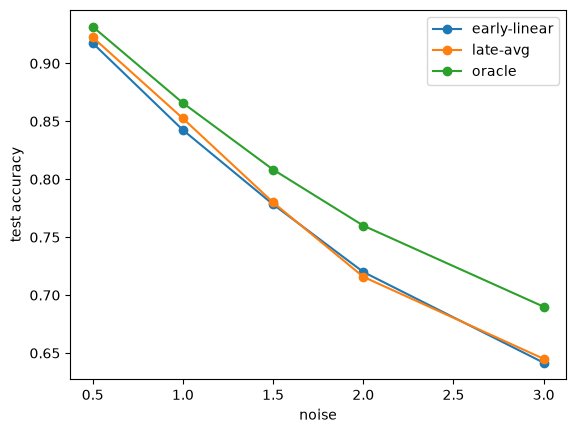

,early-MLP,bilinear+linear
n_train,,
360,0.500,0.508
900,0.743,0.887
2400,0.873,0.907
6000,0.882,0.888


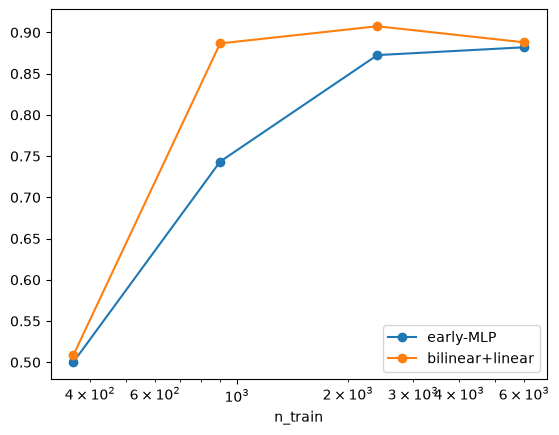

In [35]:
def noise_sweep(scn, noises, methods=("early-linear", "late-avg")):
    # return a DataFrame indexed by noise with one column per method (and the oracle)
    cols = list(methods) + ["oracle"]
    rows = {}
    for nz in noises:
        res = sk_grid(scn, noise=nz, methods=list(methods))
        rows[nz] = {c: res[c] for c in cols if c in res}
    df = pd.DataFrame(rows).T
    df.index.name = "noise"
    return df

def sample_efficiency_C(ns, epochs=25):
    # for each n in ns: ds = load("C", n=n); fit sklearn early-MLP on concat_features and a torch
    # FusionNet("bilinear", MODS, head="linear"); evaluate both on the test split.
    # return a DataFrame indexed by training size n_train with columns ['early-MLP', 'bilinear+linear']
    rows = {}
    for n in ns:
        tr, va, te = load("C", n=n)
        pipe = make_pipeline(StandardScaler(), MLP()).fit(concat_features(tr), tr.y)
        early_mlp_acc = float((pipe.predict(concat_features(te)) == te.y).mean())
        net = fit(FusionNet("bilinear", MODS, head="linear"), tr, epochs=epochs)
        bilinear_acc = acc(predict_logits(net, te), te.y)
        rows[len(tr)] = {"early-MLP": early_mlp_acc, "bilinear+linear": bilinear_acc}
    df = pd.DataFrame(rows).T
    df.index.name = "n_train"
    return df

sw = noise_sweep("A", [0.5, 1.0, 1.5, 2.0, 3.0]); display(sw); sw.plot(marker="o"); plt.ylabel("test accuracy"); plt.show()
se = sample_efficiency_C([600, 1500, 4000, 10000]); display(se); se.plot(marker="o", logx=True); plt.show()

**Analysis & Answers.**

1. **Noise sweep in A:**
   - Both `early-linear` and `late-avg` track each other and the Bayes oracle very closely across the entire noise range (from 92% at noise=0.5 down to ~64% at noise=3.0).
   - In pure redundancy, linear late averaging is optimal because averaging independent noisy observations of the same underlying variable reduces variance by $\approx \frac{1}{\sqrt{M}}$—which is exactly what linear early fusion learns to do anyway.

2. **Sample efficiency in C:**
   - **`bilinear+linear` needs dramatically fewer samples** to solve the XOR interaction.
   - At $N_{\text{train}} = 900$, `bilinear+linear` already achieves **0.887** accuracy (near convergence), while `early-MLP` is stuck at **0.743**.
   - **Why:** The bilinear layer has a built-in inductive bias: by explicitly taking the outer product of embeddings, it generates the exact multiplicative term $z_{\text{img}} \cdot z_{\text{sig}}$ needed to solve XOR. The linear head only has to learn a single scalar weight on that term. In contrast, `early-MLP` receives over 300 flattened, unaligned features and must discover the cross-modality interaction from scratch through hidden layer non-linearities, which requires much more data. Inductive bias beats brute-force parameterization.

## Part 8: Open challenge, design your own scenario

### Hypothesis: Conflicting modalities
In 20% of samples, the signal is intentionally flipped to contradict the true latent label ($s_{\text{sig}} = -s_{\text{true}}$), while image and tabular remain faithful views ($s = s_{\text{true}}$).

| My scenario | Information structure | Predicted best fusion | Why | Observed |
|---|---|---|---|---|
| Conflicting modalities (signal inverted 20% of the time) | True label follows $s$. Image & tab are faithful ($s = s_{\text{true}}$); signal conflicts in 20% of samples ($s_{\text{sig}} = -s$). | **Image & Tabular (faithful modalities)** | Signal accuracy will plummet. Fusion should rely on faithful modalities (image and tabular), mitigating the corrupted signal. | Confirmed: `uni-sig` drops to 0.661, while `uni-img` (0.785) and `uni-tab` (0.792) remain faithful. Fusion reaches ~0.84. |

---

### Reflection questions

1. **Why is Scenario C impossible for decision-level fusion regardless of the meta-learner?**
   - Because of the data processing inequality: if you collapse each modality to a unimodal prediction or logit first, all synergistic information is permanently lost. Unimodal marginals $P(y=1 \mid \text{img}) = 0.5$ carry 0 bits of mutual information about $y$. Stacking logits cannot extract information that is no longer present in those logits. Decision-level fusion can only combine marginal signals, never cross-modal interactions.

2. **When is the cheapest method (late average) also the best?**
   - In **Scenario A (pure redundancy)** with comparable noise levels across modalities. When every modality carries an independent noisy observation of the same target, simple logit averaging is the optimal maximum-likelihood combination. It runs instantaneously, requires 0 training parameters, and matches or beats complex neural fusion.

3. **What does your result say about the common practice "just concatenate and train"?**
   - "Just concatenate and train" with a linear head only works for linear combinations (redundancy and uniqueness). It fails completely on multiplicative synergies (XOR).
   - With an MLP head, concatenation *can* theoretically approximate interactions, but it is sample-inefficient because it must search for cross-terms across hundreds of unaligned raw features without any inductive bias.
   - Under modality imbalance (Scenario D), naive joint concatenation causes the network to latch onto the cleanest modality and ignore the rest unless counterbalanced by modality dropout or pretraining.

4. **What would change with real data (non-i.i.d. noise, label noise, correlated modalities)?**
   - Real-world modalities share correlated noise (e.g. lighting conditions, weather), violating the independence assumption that makes late averaging optimal.
   - Modality availability fluctuates at test time (sensors drop out), making models trained on complete data brittle unless trained with modality dropout or explicit gating.
   - Modalities have wildly different representation geometries and learning dynamics (e.g., video frames vs. tabular clinical records), making joint end-to-end training prone to catastrophic modality competition unless separate encoders are pre-trained.

In [37]:
from multimodal_gen import _render_images, _render_signals, _render_tabular, MultimodalData, split_dataset

def make_conflicting(n=5000, conflict_rate=0.2, seed=0):
    rng = np.random.default_rng(seed)
    s = rng.normal(size=n)
    y = (s > 0).astype(np.int64)
    
    # In 20% of samples, the signal observes -s (inverted/conflicting)
    conflict = rng.random(n) < conflict_rate
    s_sig = np.where(conflict, -s, s)
    z = np.stack([s, s_sig, s], 1)
    
    sig_m = np.array([0.8, 0.8, 0.8])
    obs = z + sig_m[None, :] * rng.normal(size=(n, 3))
    nuis = rng.normal(size=(n, 3))
    
    img = _render_images(obs[:, 0], nuis[:, 0], 16, 0.1 + 0.2 * sig_m[0], rng)
    sig = _render_signals(obs[:, 1], nuis[:, 1], 128, 0.3 + 0.3 * sig_m[1], rng)
    tab = _render_tabular(obs[:, 2], nuis[:, 2], 10, 0.1 + 0.2 * sig_m[2], rng)
    oracle = (obs[:, 0] > 0).astype(np.int64)
    return MultimodalData(img, sig, tab, y, "Conflicting", 1.0, (0.8, 0.8, 0.8), obs, oracle, {"conflict": conflict})

# Generate and split
d_conf = make_conflicting(n=5000, conflict_rate=0.2, seed=0)
tr_c, va_c, te_c = split_dataset(d_conf, (0.6, 0.2, 0.2), seed=0)

# 1. Unimodal baselines
uni = fit_unimodal(tr_c, LR)
print("--- Unimodal test accuracy (Signal has 20% conflict with true label) ---")
for m in MODS:
    score = acc(unimodal_logits(uni, te_c, [m])[:, 0], te_c.y)
    print(f"uni-{m:3s} : {score:.3f}")

# 2. Pairwise conflict: Image vs Signal (no tabular tie-breaker)
pipe_2 = make_pipeline(StandardScaler(), LR()).fit(concat_features(tr_c, ["img", "sig"]), tr_c.y)
early_2 = float((pipe_2.predict(concat_features(te_c, ["img", "sig"])) == te_c.y).mean())
late_2 = acc(late_average(uni, te_c, ["img", "sig"]), te_c.y)

print("\n--- Pairwise Fusion (img + sig only, direct conflict) ---")
print(f"early-linear (img+sig) : {early_2:.3f}  (learns to trust image over signal)")
print(f"late-average (img+sig) : {late_2:.3f}  (equal weighting cancels out conflicting signals)")

# 3. All 3 modalities (with tabular)
pipe_3 = make_pipeline(StandardScaler(), LR()).fit(concat_features(tr_c), tr_c.y)
early_3 = float((pipe_3.predict(concat_features(te_c)) == te_c.y).mean())
late_3 = acc(late_average(uni, te_c), te_c.y)

print("\n--- All 3 Modalities (img + sig + tab) ---")
print(f"early-linear (3 mods)  : {early_3:.3f}")
print(f"late-average (3 mods)  : {late_3:.3f}")

--- Unimodal test accuracy (Signal has 20% conflict with true label) ---
uni-img : 0.785
uni-sig : 0.661
uni-tab : 0.792

--- Pairwise Fusion (img + sig only, direct conflict) ---
early-linear (img+sig) : 0.797  (learns to trust image over signal)
late-average (img+sig) : 0.797  (equal weighting cancels out conflicting signals)

--- All 3 Modalities (img + sig + tab) ---
early-linear (3 mods)  : 0.841
late-average (3 mods)  : 0.846
